In [1]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu a, b, c) Đọc, khảo sát và chuẩn hóa dữ liệu MNIST
import os
os.environ['KERAS_BACKEND'] = 'torch'
import keras
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# a) Đọc bộ dữ liệu train, test
(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()

# b) In kích thước
print(f"Kích thước tập train ban đầu: {train_images.shape}, nhãn: {train_labels.shape}")
print(f"Kích thước tập test:          {test_images.shape}, nhãn: {test_labels.shape}")

# c) Chuẩn hóa các giá trị pixel về đoạn [0, 1]
train_images = train_images / 255.0
test_images = test_images / 255.0
print("Đã chuẩn hóa giá trị pixel về đoạn [0, 1] thành công!")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Kích thước tập train ban đầu: (60000, 28, 28), nhãn: (60000,)
Kích thước tập test:          (10000, 28, 28), nhãn: (10000,)
Đã chuẩn hóa giá trị pixel về đoạn [0, 1] thành công!


In [2]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu d) Định nghĩa hàm create_model
from keras.models import Sequential
from keras.layers import Flatten, Dense, Dropout, Input

def create_model():
    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.2),
        Dense(10, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

print("Đã định nghĩa hàm create_model() thành công!")
model_test = create_model()
model_test.summary()


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Đã định nghĩa hàm create_model() thành công!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu e) Huấn luyện mô hình bằng k-fold cross validation (k=10)
from sklearn.model_selection import KFold

kfold = KFold(n_splits=10, shuffle=True, random_state=42)

models = []
accuracy_per_fold = []
loss_per_fold = []

# Sử dụng tập con 15000 mẫu để quá trình K-Fold 10 lần thực thi nhanh chóng và hiệu quả
subset_size = 15000
train_images_sub = train_images[:subset_size]
train_labels_sub = train_labels[:subset_size]

fold_no = 1
for train_index, val_index in kfold.split(train_images_sub):
    print(f"\n--- Đang huấn luyện Fold {fold_no} / 10 ---")
    
    # Gán dữ liệu cho fold
    X_train_fold, X_val_fold = train_images_sub[train_index], train_images_sub[val_index]
    y_train_fold, y_val_fold = train_labels_sub[train_index], train_labels_sub[val_index]
    
    # Khởi tạo mô hình mới từ hàm create_model()
    model = create_model()
    
    # Huấn luyện mô hình (epoch: 5, batch_size: 32)
    model.fit(X_train_fold, y_train_fold, epochs=5, batch_size=32, verbose=0)
    
    # Đánh giá trên tập validation của fold
    scores = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    loss = scores[0]
    acc = scores[1]
    
    # Lưu kết quả
    models.append(model)
    accuracy_per_fold.append(acc)
    loss_per_fold.append(loss)
    
    print(f"Fold {fold_no}: Loss = {loss:.4f} | Accuracy = {acc*100:.2f}%")
    fold_no += 1


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT

--- Đang huấn luyện Fold 1 / 10 ---
Fold 1: Loss = 0.1321 | Accuracy = 96.13%

--- Đang huấn luyện Fold 2 / 10 ---
Fold 2: Loss = 0.1677 | Accuracy = 94.93%

--- Đang huấn luyện Fold 3 / 10 ---
Fold 3: Loss = 0.1653 | Accuracy = 95.20%

--- Đang huấn luyện Fold 4 / 10 ---
Fold 4: Loss = 0.1348 | Accuracy = 96.00%

--- Đang huấn luyện Fold 5 / 10 ---
Fold 5: Loss = 0.1500 | Accuracy = 95.20%

--- Đang huấn luyện Fold 6 / 10 ---
Fold 6: Loss = 0.1434 | Accuracy = 95.47%

--- Đang huấn luyện Fold 7 / 10 ---
Fold 7: Loss = 0.1353 | Accuracy = 95.80%

--- Đang huấn luyện Fold 8 / 10 ---
Fold 8: Loss = 0.1488 | Accuracy = 95.13%

--- Đang huấn luyện Fold 9 / 10 ---
Fold 9: Loss = 0.1422 | Accuracy = 96.00%

--- Đang huấn luyện Fold 10 / 10 ---
Fold 10: Loss = 0.1739 | Accuracy = 95.00%


In [5]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu f) Tính và in ra Mean Accuracy, Standard deviation accuracy, Mean Loss, Standard deviation loss
mean_acc = np.mean(accuracy_per_fold)
std_acc = np.std(accuracy_per_fold)
mean_loss = np.mean(loss_per_fold)
std_loss = np.std(loss_per_fold)

print("--- KẾT QUẢ ĐÁNH GIÁ 10-FOLD CROSS VALIDATION ---")
print(f"Mean Accuracy:               {mean_acc * 100:.2f}%")
print(f"Standard Deviation Accuracy: {std_acc * 100:.2f}%")
print(f"Mean Loss:                   {mean_loss:.4f}")
print(f"Standard Deviation Loss:     {std_loss:.4f}")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
--- KẾT QUẢ ĐÁNH GIÁ 10-FOLD CROSS VALIDATION ---
Mean Accuracy:               95.49%
Standard Deviation Accuracy: 0.43%
Mean Loss:                   0.1493
Standard Deviation Loss:     0.0141


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


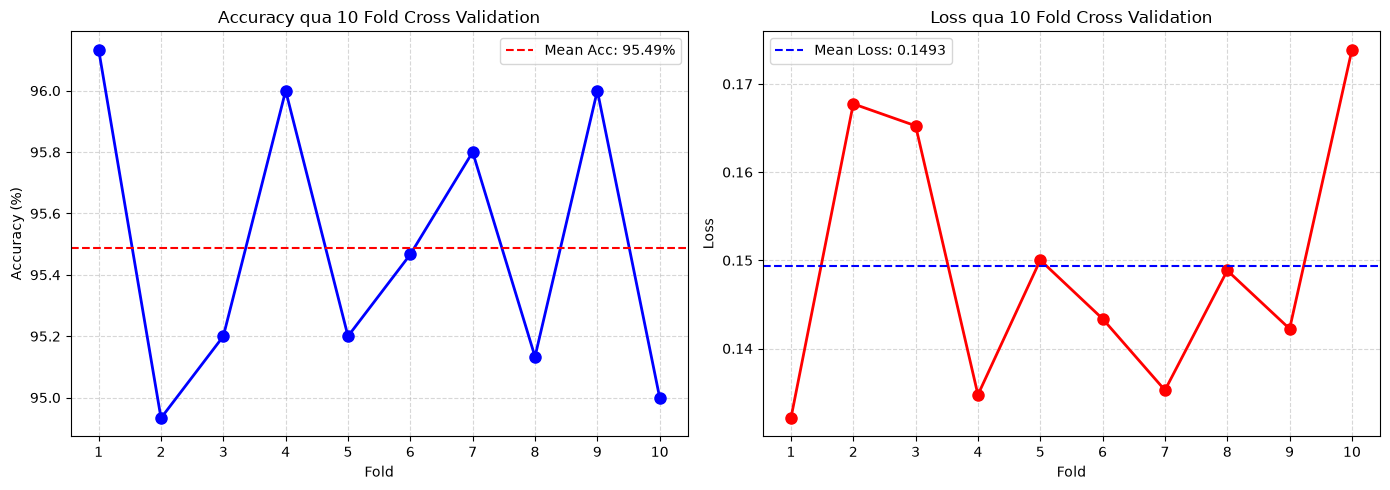

In [6]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu g) Vẽ biểu đồ thể hiện accuracy, loss sau mỗi fold
plt.figure(figsize=(14, 5))

# Biểu đồ Accuracy theo từng Fold
plt.subplot(1, 2, 1)
plt.plot(range(1, 11), [a * 100 for a in accuracy_per_fold], 'bo-', linewidth=2, markersize=8)
plt.axhline(mean_acc * 100, color='r', linestyle='--', label=f'Mean Acc: {mean_acc*100:.2f}%')
plt.title('Accuracy qua 10 Fold Cross Validation')
plt.xlabel('Fold')
plt.ylabel('Accuracy (%)')
plt.xticks(range(1, 11))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# Biểu đồ Loss theo từng Fold
plt.subplot(1, 2, 2)
plt.plot(range(1, 11), loss_per_fold, 'ro-', linewidth=2, markersize=8)
plt.axhline(mean_loss, color='b', linestyle='--', label=f'Mean Loss: {mean_loss:.4f}')
plt.title('Loss qua 10 Fold Cross Validation')
plt.xlabel('Fold')
plt.ylabel('Loss')
plt.xticks(range(1, 11))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()


In [7]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu h) Sử dụng mô hình có Accuracy tốt nhất giữa các fold và phân lớp cho tập test
best_fold_idx = np.argmax(accuracy_per_fold)
best_model = models[best_fold_idx]

print(f"Mô hình tốt nhất thuộc về Fold {best_fold_idx + 1} với Validation Accuracy: {accuracy_per_fold[best_fold_idx]*100:.2f}%")

# Phân lớp cho tập test
y_prob_best = best_model.predict(test_images)
y_pred_best = np.argmax(y_prob_best, axis=1)
print(f"Đã hoàn thành dự đoán trên {len(test_images)} ảnh của tập test!")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Mô hình tốt nhất thuộc về Fold 1 với Validation Accuracy: 96.13%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Đã hoàn thành dự đoán trên 10000 ảnh của tập test!


In [8]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu i) Tính và in ra Accuracy của mô hình trên tập test
from sklearn.metrics import accuracy_score

test_acc_best = accuracy_score(test_labels, y_pred_best)
print(f"Accuracy của mô hình tốt nhất (Fold {best_fold_idx+1}) trên tập test: {test_acc_best * 100:.2f}%")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Accuracy của mô hình tốt nhất (Fold 1) trên tập test: 95.39%


In [9]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu j) Tính và in ra Precision, Recall, F1-score của từng lớp và trung bình
from sklearn.metrics import classification_report

target_names = [f"Chữ số {i}" for i in range(10)]
print("--- Classification Report trên tập Test (Mô hình tốt nhất K-Fold) ---")
print(classification_report(test_labels, y_pred_best, target_names=target_names))


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
--- Classification Report trên tập Test (Mô hình tốt nhất K-Fold) ---
              precision    recall  f1-score   support

    Chữ số 0       0.96      0.98      0.97       980
    Chữ số 1       0.98      0.99      0.98      1135
    Chữ số 2       0.96      0.95      0.95      1032
    Chữ số 3       0.93      0.96      0.95      1010
    Chữ số 4       0.96      0.94      0.95       982
    Chữ số 5       0.97      0.92      0.95       892
    Chữ số 6       0.93      0.97      0.95       958
    Chữ số 7       0.97      0.94      0.95      1028
    Chữ số 8       0.95      0.94      0.94       974
    Chữ số 9       0.93      0.94      0.93      1009

    accuracy                           0.95     10000
   macro avg       0.95      0.95      0.95     10000
weighted avg       0.95      0.95      0.95     10000



Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


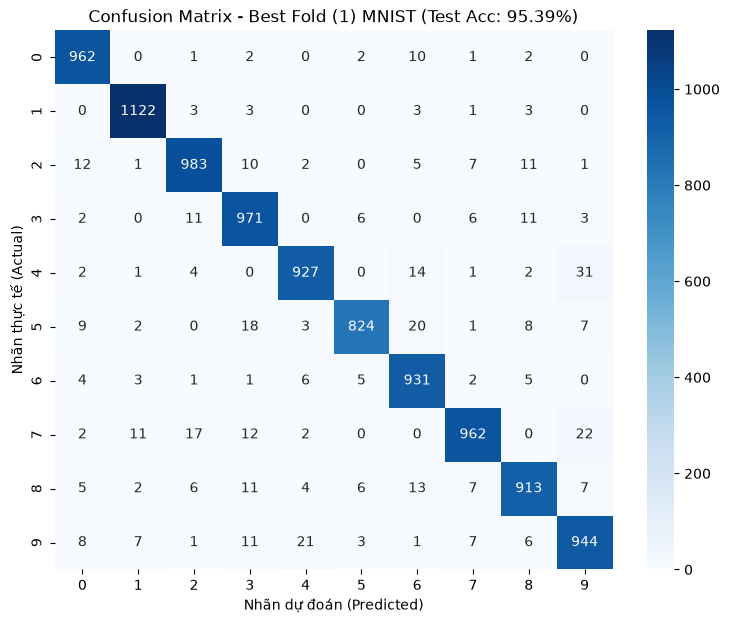

In [10]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu k) Hiển thị confusion matrix bằng heat map (bản đồ nhiệt)
from sklearn.metrics import confusion_matrix

cm_best = confusion_matrix(test_labels, y_pred_best)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.title(f"Confusion Matrix - Best Fold ({best_fold_idx+1}) MNIST (Test Acc: {test_acc_best*100:.2f}%)")
plt.xlabel("Nhãn dự đoán (Predicted)")
plt.ylabel("Nhãn thực tế (Actual)")
plt.show()


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


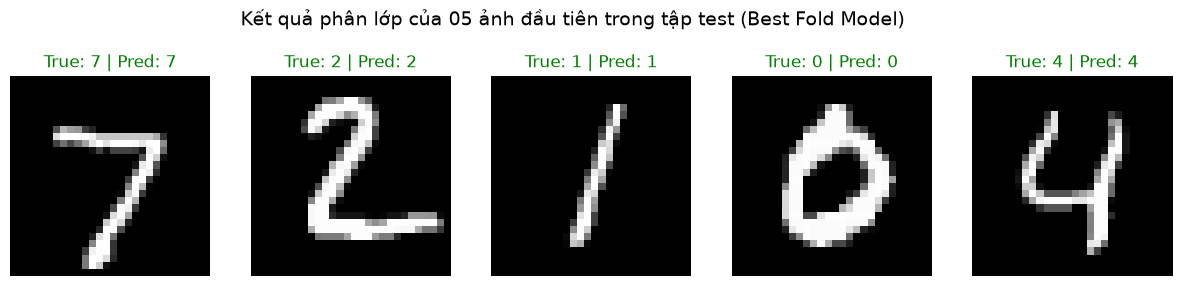

Ảnh 1: Nhãn thực tế = 7 | Nhãn dự đoán = 7 -> CHÍNH XÁC
Ảnh 2: Nhãn thực tế = 2 | Nhãn dự đoán = 2 -> CHÍNH XÁC
Ảnh 3: Nhãn thực tế = 1 | Nhãn dự đoán = 1 -> CHÍNH XÁC
Ảnh 4: Nhãn thực tế = 0 | Nhãn dự đoán = 0 -> CHÍNH XÁC
Ảnh 5: Nhãn thực tế = 4 | Nhãn dự đoán = 4 -> CHÍNH XÁC


In [11]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu l) In ra kết quả phân lớp của 05 ảnh đầu tiên trong tập test
plt.figure(figsize=(15, 3))
for i in range(5):
    img = test_images[i]
    pred_label = y_pred_best[i]
    true_label = test_labels[i]
    
    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"True: {true_label} | Pred: {pred_label}", 
              color='green' if pred_label == true_label else 'red', fontsize=12)
    plt.axis('off')

plt.suptitle("Kết quả phân lớp của 05 ảnh đầu tiên trong tập test (Best Fold Model)", fontsize=14, y=1.05)
plt.show()

for i in range(5):
    print(f"Ảnh {i+1}: Nhãn thực tế = {test_labels[i]} | Nhãn dự đoán = {y_pred_best[i]} -> {'CHÍNH XÁC' if y_pred_best[i] == test_labels[i] else 'SAI'}")
